In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.optimize import curve_fit
from scipy.stats import linregress
import pandas as pd

# Fetch data

BaCBM2 standard curve:
a = 0.010035585585585585
b = 0.003012612612612653
R = 0.9999224554755494


Text(0.5, 1.0, 'BaCBM2 standard curve, R = 0.9999')

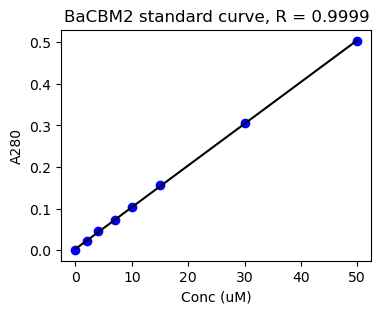

In [10]:
df = pd.read_csv("data/Avicel_BaCBM2_std.txt", sep = '\t', decimal = ',')
df['std'] = df['std']-df['std'][0]

# BaCBM2
result = linregress(df['conc'], df['std'])

a = result.slope
b = result.intercept

print('BaCBM2 standard curve:')
print('a = ' + str(result.slope))
print('b = ' + str(result.intercept))
print('R = ' + str(result.rvalue))   # correlation

plt.figure(figsize=(4, 3))
plt.plot(df['conc'], df['std'], 'bo')
plt.plot(df['conc'], a*df['conc'] + b, 'k')
plt.xlabel('Conc (uM)')
plt.ylabel('A280')
plt.title('BaCBM2 standard curve, R = ' + str(f"{result.rvalue:.4f}"))

In [11]:
def create_df(filepath, a, b, subst_conc):
    # a = slope of std curve, b = intercept of std curve, subst_conc = g/L substrate
    df = pd.read_csv(filepath, sep = '\t', decimal = ',') #load file

    #zero with blank
    blank = np.average([df['A'][0],df['B'][0],df['C'][0]])
    df['A'] = df['A']-blank
    df['B'] = df['B']-blank
    df['C'] = df['C']-blank

    #calculate Pfree
    df['F1'] = (df['A']-b)/a
    df['F2'] = (df['B']-b)/a
    df['F3'] = (df['C']-b)/a

    #calculate Pbound
    df['B1'] = df['conc'] - df['F1'] #uM
    df['B2'] = df['conc'] - df['F2'] 
    df['B3'] = df['conc'] - df['F3'] 
    
    df['B1'] = df['B1']/subst_conc #umol/g chitin
    df['B2'] = df['B2']/subst_conc 
    df['B3'] = df['B3']/subst_conc 

    #calculate averages
    df['P_free_avg'] = df[['F1', 'F2', 'F3']].mean(axis=1)
    df['std_f'] = df[['F1', 'F2', 'F3']].std(axis=1)
    df['P_bound_avg'] = df[['B1', 'B2', 'B3']].mean(axis=1)
    df['P_bound_std'] = df[['B1', 'B2', 'B3']].std(axis=1)

    return df

def calc_bound_P(P,Kd,Bmax): 
    return Bmax*P/(Kd+P)

In [12]:
df1 = create_df("data/Avicel_BaCBM2_assay.txt", a, b, 10) #BaCBM2, avicel
df1

,conc,A,B,C,F1,F2,F3,B1,B2,B3,P_free_avg,std_f,P_bound_avg,P_bound_std
0,0,0.0007,6.938894e-18,-0.0007,-0.230441,-0.300193,-0.369945,0.023044,0.030019,0.036994,-0.300193,0.069752,0.030019,0.006975
1,2,0.0127,1.270000e-02,0.0134,0.965304,0.965304,1.035055,0.103470,0.103470,0.096494,0.988554,0.040271,0.101145,0.004027
2,4,0.0276,2.860000e-02,0.0293,2.450020,2.549666,2.619417,0.154998,0.145033,0.138058,2.539701,0.085137,0.146030,0.008514
3,7,0.0500,5.290000e-02,0.0536,4.682077,4.971049,5.040801,0.231792,0.202895,0.195920,4.897976,0.190198,0.210202,0.019020
4,10,0.0736,7.900000e-02,0.0771,7.033709,7.571794,7.382468,0.296629,0.242821,0.261753,7.329324,0.272951,0.267068,0.027295
5,15,0.1159,1.111000e-01,0.1194,11.248710,10.770412,11.597468,0.375129,0.422959,0.340253,11.205530,0.415216,0.379447,0.041522
6,30,0.2303,2.215000e-01,0.2489,22.648144,21.771264,24.501549,0.735186,0.822874,0.549845,22.973652,1.393944,0.702635,0.139394
7,50,0.3776,4.173000e-01,0.4346,37.325912,41.281835,43.005700,1.267409,0.871817,0.699430,40.537816,2.912073,0.946218,0.291207


In [13]:
df_CNF = pd.read_excel('data/data_mech_CNF.xlsx')
df_avi = pd.read_excel('data/data_avicel.xlsx')
df_CNC = pd.read_excel('data/data_CNC.xlsx')

#Calculate standard deviations

list = df_CNF, df_avi, df_CNC

for df in list:
    df['P_bound_std'] = df[['P_bound_7', 'P_bound_8', 'P_bound_9']].std(axis=1)    
    
# Vol = 200 uL, conc substrate = 10 g/L, => 0.0002L/(10g*00002L) = /10g
## Only for Avicel
df_avi['P_bound_std'] = df_avi['P_bound_std']/10
df_avi['P_bound_avg'] = df_avi['P_bound_avg']/10

df_avi

,Conc ScCBM2 (nM),Conc (uM),7,8,9,P_free_7,P_free_8,P_free_9,P_free_avg,P_bound_7,P_bound_8,P_bound_9,P_bound_avg,P_bound_std
0,0,0.0,0.0000,0.0000,0.0000,-0.178295,-0.178295,-0.178295,-0.178295,0.178295,0.178295,0.178295,0.017829,0.000000
1,2000,2.0,0.0053,0.0066,0.0028,0.232558,0.333333,0.038760,0.201550,1.767442,1.666667,1.961240,0.179845,0.014971
2,4000,4.0,0.0127,0.0127,0.0087,0.806201,0.806201,0.496124,0.702842,3.193799,3.193799,3.503876,0.329716,0.017902
3,5600,5.6,0.0299,0.0226,0.0219,2.139535,1.573644,1.519380,1.744186,3.460465,4.026356,4.080620,0.385581,0.034346
4,8000,8.0,0.0382,0.0286,0.0241,2.782946,2.038760,1.689922,2.170543,5.217054,5.961240,6.310078,0.582946,0.055830
5,11500,11.5,0.0504,0.0404,0.0488,3.728682,2.953488,3.604651,3.428941,7.771318,8.546512,7.895349,0.807106,0.041640
6,16000,16.0,0.0637,0.0648,0.0689,4.759690,4.844961,5.162790,4.922481,11.240310,11.155039,10.837210,1.107752,0.021244
7,21000,21.0,0.1180,0.1093,0.1057,8.968993,8.294573,8.015503,8.426357,12.031007,12.705427,12.984497,1.257364,0.049021


ScCBM2 standard curve:
a = 0.008206878427787934
b = 0.0005075639853747982
R = 0.999834082731509
BaCBM2 standard curve:
a = 0.009854836989640462
b = -0.0013360984156002287
R = 0.9994869906398061


Text(0.5, 1.0, 'BaCBM2 standard curve, R = 0.9995')

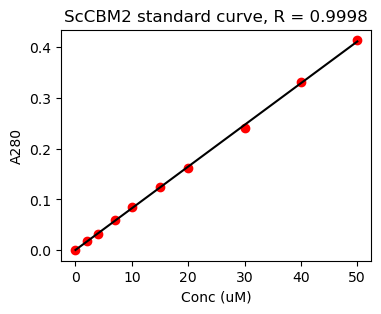

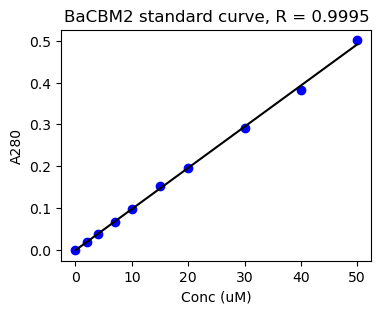

In [14]:
df = pd.read_csv("data/BaScCBM2_std_150uL.txt", sep = '\t', decimal = ',')
df['Sc'] = df['Sc']-df['Sc'][0]
df['Ba'] = df['Ba']-df['Ba'][0]

# ScCBM2
result = linregress(df['conc'], df['Sc'])

Sc_a = result.slope
Sc_b = result.intercept

print('ScCBM2 standard curve:')
print('a = ' + str(result.slope))
print('b = ' + str(result.intercept))
print('R = ' + str(result.rvalue))   # correlation

plt.figure(figsize=(4, 3))
plt.plot(df['conc'], df['Sc'], 'ro')
plt.plot(df['conc'], Sc_a*df['conc'] + Sc_b, 'k')
plt.xlabel('Conc (uM)')
plt.ylabel('A280')
plt.title('ScCBM2 standard curve, R = ' + str(f"{result.rvalue:.4f}"))

# BaCBM2
result = linregress(df['conc'], df['Ba'])

Ba_a = result.slope
Ba_b = result.intercept

print('BaCBM2 standard curve:')
print('a = ' + str(result.slope))
print('b = ' + str(result.intercept))
print('R = ' + str(result.rvalue))   # correlation

plt.figure(figsize=(4, 3))
plt.plot(df['conc'], df['Ba'], 'bo')
plt.plot(df['conc'], Ba_a*df['conc'] + Ba_b, 'k')
plt.xlabel('Conc (uM)')
plt.ylabel('A280')
plt.title('BaCBM2 standard curve, R = ' + str(f"{result.rvalue:.4f}"))

In [7]:
df_Sc_a_chitin = create_df("data/ScCBM2_a-chitin_150uL.txt", Sc_a, Sc_b, 10) #ScCBM2, a-chitin
df_Ba_a_chitin = create_df("data/BaCBM2_a-chitin_150uL.txt", Ba_a, Ba_b, 10) #BaCBM2, a-chitin
df_Sc_b_chitin = create_df("data/ScCBM2_b-chitin_150uL.txt", Sc_a, Sc_b, 10) #ScCBM2, b-chitin
df_Ba_b_chitin = create_df("data/BaCBM2_b-chitin_150uL.txt", Ba_a, Ba_b, 10) #BaCBM2, b-chitin

# plot data

In [31]:
def plot_curve(df, ax, label, color, style, decimal_K, decimal_B, second=False):
    Pfree = df['P_free_avg']       #uM
    Pbound = df['P_bound_avg']     #umol/g
    yerr = df['P_bound_std']       #umol/g

    # Fit to Langmuir
    popt, pcov = curve_fit(calc_bound_P, Pfree, Pbound)
    error = np.sqrt(np.diag(pcov))
    
    # Plot
    x_values = np.linspace(0, df['P_free_avg'].iloc[-1], 100)
    ax.plot(x_values, calc_bound_P(x_values, popt[0], popt[1]), color=color, linewidth = 0.9, linestyle='--')
    ax.errorbar(Pfree, Pbound, yerr=yerr, color=color, marker=style, markersize = 3, linestyle='None', elinewidth = 0.5, capsize = 2)
    #ax.plot(Pfree,Pbound, linestyle = 'None', label = label)
    
    ax.set_title(label, fontweight='bold', pad=2)

    Kd = popt[0]
    Bmax = popt[1]

    if second==True:
        ax.text(
            0.05, 0.77,                  # x, y in axis coordinates (0 to 1)
            '$K_\mathrm{d}$ = ' + f"{Kd:.{decimal_K}f}" + u"\u00B1" + f"{error[0]:.{decimal_K}f}" + " $\mathrm{\mu}$M\n$B_\mathrm{max}$ = " + f"{Bmax:.{decimal_B}f}" + u"\u00B1" + f"{error[1]:.{decimal_B}f}" + " $\mathrm{\mu}$mol/g",   # text content
            transform=ax.transAxes,  # interpret coords relative to axes
            fontsize=7,
            linespacing=1,
            color=color,
            ha = 'left', va = 'top',
            bbox=dict(boxstyle='round', facecolor='none', edgecolor='none', alpha=0.8)
        )
    else:    
        ax.text(
            0.05, 0.97,                  # x, y in axis coordinates (0 to 1)
            '$K_\mathrm{d}$ = ' + f"{Kd:.{decimal_K}f}" + u"\u00B1" + f"{error[0]:.{decimal_K}f}" + " $\mathrm{\mu}$M\n$B_\mathrm{max}$ = " + f"{Bmax:.{decimal_B}f}" + u"\u00B1" + f"{error[1]:.{decimal_B}f}" + " $\mathrm{\mu}$mol/g",   # text content
            transform=ax.transAxes,  # interpret coords relative to axes
            fontsize=7,
            linespacing=1,
            color = color,
            ha = 'left', va = 'top',
            bbox=dict(boxstyle='round', facecolor='none', edgecolor='none', alpha=0.8)
        )

    # Print parameters
    print(label + ':')
    print('Kd = ' + str(popt[0]) + u"\u00B1" + str(error[0]) + "uM")
    print('Bmax = ' + str(popt[1]) + u"\u00B1" + str(error[1]) + "umol/g")

    return Kd, Bmax

Avicel:
Kd = 5.875182928117629±2.1269274734019uM
Bmax = 2.2055516681704295±0.44307026368579006umol/g
Avicel:
Kd = 42.268540907389145±9.830071780805282uM
Bmax = 1.9411583818475535±0.2792314262056076umol/g
$\mathbf{\alpha}$-chitin:
Kd = 11.723535833166547±8.488284232507807uM
Bmax = 0.5693929314691015±0.16337109338721686umol/g
$\mathbf{\alpha}$-chitin:
Kd = 37.51469801264102±11.21564378629855uM
Bmax = 2.010769343346862±0.37471884107231734umol/g
CNF:
Kd = 12.181043523907952±3.9526671857023072uM
Bmax = 6.868871502946087±1.411385043514778umol/g
CNC:
Kd = 102.83799000729174±92.88954275960731uM
Bmax = 10.928075058618258±8.237176025249802umol/g
$\mathbf{\beta}$-chitin:
Kd = 12.916153612331325±3.8728830169830095uM
Bmax = 6.141833092682588±1.2461403438314225umol/g
$\mathbf{\beta}$-chitin:
Kd = 30.94777159639185±8.089386493323092uM
Bmax = 8.244507274278197±1.685434943379397umol/g


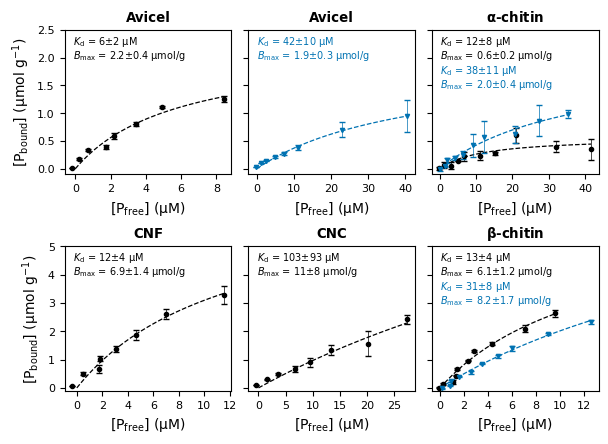

In [26]:
width_mm = 175
width_in = width_mm / 25.4 
height_in = 2*85*0.7/25.4

plt.rcParams.update({
    "font.size": 8,        # base font size
    "axes.labelsize": 10,   # axis labels
    "xtick.labelsize": 8,  # x tick labels
    "ytick.labelsize": 8,  # y tick labels
    "legend.fontsize": 10,  # legend
})

fig, axs = plt.subplots(2, 3, sharey='row', figsize=(width_in, height_in))
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=0.5)

plot_curve(df_avi, axs[0,0], 'Avicel', 'k', 'o', 0, 1) #ScCBM2, Avicel
plot_curve(df1, axs[0,1], 'Avicel', "#0072B2", 'v', 0, 1) #BaCBM2, Avicel
plot_curve(df_Sc_a_chitin, axs[0,2], r'$\mathbf{\alpha}$-chitin', 'k', 'o', 0, 1) #ScCBM2, a-chitin
plot_curve(df_Ba_a_chitin, axs[0,2], r'$\mathbf{\alpha}$-chitin', "#0072B2", 'v', 0, 1, True) #BaCBM2, a-chitin

plot_curve(df_CNF, axs[1,0], 'CNF', 'k', 'o', 0, 1) #ScCBM2, CNF
plot_curve(df_CNC, axs[1,1], 'CNC', 'k', 'o', 0, 0) #ScCBM2, CNC
plot_curve(df_Sc_b_chitin, axs[1,2], r'$\mathbf{\beta}$-chitin', 'k', 'o', 0, 1) #ScCBM2, b-chitin
plot_curve(df_Ba_b_chitin, axs[1,2], r'$\mathbf{\beta}$-chitin', "#0072B2", 'v', 0, 1, True) #BaCBM2, b-chitin

axs[0,0].xaxis.set_major_locator(MultipleLocator(2))
axs[0,1].xaxis.set_major_locator(MultipleLocator(10))
axs[0,2].xaxis.set_major_locator(MultipleLocator(10))
axs[1,0].xaxis.set_major_locator(MultipleLocator(2))
axs[1,1].xaxis.set_major_locator(MultipleLocator(5))
axs[1,2].xaxis.set_major_locator(MultipleLocator(2))

axs[0,0].set_ylabel('[P$_{\mathrm{bound}}$] ($\mathrm{\mu}$mol g$^{-1}$)')
axs[1,0].set_ylabel('[P$_{\mathrm{bound}}$] ($\mathrm{\mu}$mol g$^{-1}$)')
axs[0,0].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')
axs[0,1].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')
axs[0,2].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')
axs[1,0].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')
axs[1,1].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')
axs[1,2].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')

axs[0, 0].set_ylim(-0.1, 2.5)
axs[1, 0].set_ylim(-0.1, 5)

plt.savefig('plots/cel_chi_binding.png', dpi = 600, bbox_inches='tight')
plt.savefig('plots/cel_chi_binding.pdf', dpi = 600, bbox_inches='tight')

Avicel:
Kd = 5.875182928117629±2.1269274734019uM
Bmax = 2.2055516681704295±0.44307026368579006umol/g
Avicel:
Kd = 42.268540907389145±9.830071780805282uM
Bmax = 1.9411583818475535±0.2792314262056076umol/g
$\mathbf{\alpha}$-chitin:
Kd = 11.723535833166547±8.488284232507807uM
Bmax = 0.5693929314691015±0.16337109338721686umol/g
$\mathbf{\alpha}$-chitin:
Kd = 37.51469801264102±11.21564378629855uM
Bmax = 2.010769343346862±0.37471884107231734umol/g
$\mathbf{\beta}$-chitin:
Kd = 12.916153612331325±3.8728830169830095uM
Bmax = 6.141833092682588±1.2461403438314225umol/g
$\mathbf{\beta}$-chitin:
Kd = 30.94777159639185±8.089386493323092uM
Bmax = 8.244507274278197±1.685434943379397umol/g
CNF:
Kd = 12.181043523907952±3.9526671857023072uM
Bmax = 6.868871502946087±1.411385043514778umol/g
CNC:
Kd = 102.83799000729174±92.88954275960731uM
Bmax = 10.928075058618258±8.237176025249802umol/g


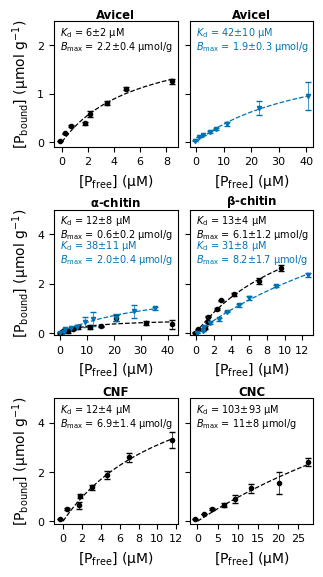

In [38]:
width_mm = 85
width_in = width_mm / 25.4 
height_in = 3*85*0.65/25.4

plt.rcParams.update({
    "font.size": 7,        # base font size
    "axes.labelsize": 10,   # axis labels
    "xtick.labelsize": 8,  # x tick labels
    "ytick.labelsize": 8,  # y tick labels
    "legend.fontsize": 10,  # legend
})

fig, axs = plt.subplots(3, 2, sharey='row', figsize=(width_in, height_in))
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=0.5)

plot_curve(df_avi, axs[0,0], 'Avicel', 'k', 'o', 0, 1) #ScCBM2, Avicel
plot_curve(df1, axs[0,1], 'Avicel', "#0072B2", 'v', 0, 1) #BaCBM2, Avicel

plot_curve(df_Sc_a_chitin, axs[1,0], r'$\mathbf{\alpha}$-chitin', 'k', 'o', 0, 1) #ScCBM2, a-chitin
plot_curve(df_Ba_a_chitin, axs[1,0], r'$\mathbf{\alpha}$-chitin', "#0072B2", 'v', 0, 1, True) #BaCBM2, a-chitin

plot_curve(df_Sc_b_chitin, axs[1,1], r'$\mathbf{\beta}$-chitin', 'k', 'o', 0, 1) #ScCBM2, b-chitin
plot_curve(df_Ba_b_chitin, axs[1,1], r'$\mathbf{\beta}$-chitin', "#0072B2", 'v', 0, 1, True) #BaCBM2, b-chitin

plot_curve(df_CNF, axs[2,0], 'CNF', 'k', 'o', 0, 1) #ScCBM2, CNF
plot_curve(df_CNC, axs[2,1], 'CNC', 'k', 'o', 0, 0) #ScCBM2, CNC


axs[0,0].xaxis.set_major_locator(MultipleLocator(2))
axs[0,1].xaxis.set_major_locator(MultipleLocator(10))
axs[1,0].xaxis.set_major_locator(MultipleLocator(10))
axs[1,1].xaxis.set_major_locator(MultipleLocator(2))
axs[2,0].xaxis.set_major_locator(MultipleLocator(2))
axs[2,1].xaxis.set_major_locator(MultipleLocator(5))


axs[0,0].set_ylabel('[P$_{\mathrm{bound}}$] ($\mathrm{\mu}$mol g$^{-1}$)')
axs[1,0].set_ylabel('[P$_{\mathrm{bound}}$] ($\mathrm{\mu}$mol g$^{-1}$)')
axs[2,0].set_ylabel('[P$_{\mathrm{bound}}$] ($\mathrm{\mu}$mol g$^{-1}$)')

axs[0,0].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')
axs[0,1].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')
axs[1,0].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')
axs[1,1].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')
axs[2,0].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')
axs[2,1].set_xlabel('[P$_{\mathrm{free}}$] ($\mathrm{\mu}$M)')

axs[0, 0].set_ylim(-0.1, 2.5)
axs[1, 0].set_ylim(-0.1, 5)
axs[2, 0].set_ylim(-0.1, 5)

plt.savefig('plots/cel_chi_binding_1col.png', dpi = 600, bbox_inches='tight')
plt.savefig('plots/cel_chi_binding_1col.pdf', dpi = 600, bbox_inches='tight')
plt.savefig('plots/cel_chi_binding_1col.svg',bbox_inches='tight')